# Buổi H4: Thẻ mô hình và báo cáo trung thực

**Hiện trường.** Mô hình sắp được giao cho đội chăm sóc khách hàng. Họ hỏi: "Nó đúng bao nhiêu phần trăm? Với khách ở Cần Thơ có đúng như ở TP.HCM không? Nó không nên dùng cho trường hợp nào?". Một con số "độ chính xác 66%" không trả lời được những câu đó.

Buổi này dạy viết **thẻ mô hình** (model card): một trang nói thật về mục đích, dữ liệu, chất lượng kèm **khoảng tin cậy**, chất lượng theo **nhóm**, độ **hiệu chuẩn**, **giới hạn** và cách dùng. Mọi con số trong thẻ được **sinh ra từ code**, không gõ tay.

**Ẩn dụ:** tờ hướng dẫn trong hộp thuốc. Không chỉ nói thuốc chữa gì, mà còn nói ai không nên dùng, tác dụng phụ, liều tối đa.

**Mindset của người làm dữ liệu:** báo cáo trung thực là nói cả những chỗ mô hình **yếu**, cùng độ không chắc của chính con số.

**Lưu ý:** dữ liệu khách hàng dựng có chủ đích; dùng để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: một con số tổng che giấu nhóm yếu |
| Chặng 1 | Khoảng tin cậy bằng bootstrap |
| Chặng 2 | Chất lượng theo nhóm và cỡ mẫu từng nhóm |
| Chặng 3 | Hiệu chuẩn: nói 70% thì có đúng 70% không |
| Chặng 4 | Giới hạn: ngoài vùng đã học |
| Chặng 5 | Sinh thẻ mô hình từ các con số |

## Chặng 0: Thấy ngay, con số tổng che giấu nhóm yếu

**Câu hỏi:** độ chính xác chung là bao nhiêu, và theo từng thành phố thì sao?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
def make_customers(n, seed, month=0):
    """Synthetic customer table (built on purpose for teaching). month > 0 makes later data drift."""
    r = np.random.RandomState(seed)
    tenure = r.gamma(3.0, 6.0, n).round(0).clip(1, 72)
    plan = r.choice(["basic", "plus", "premium"], n, p=[0.55 - 0.03 * month, 0.30, 0.15 + 0.03 * month])
    city = r.choice(["HCM", "HN", "DN", "CT"], n, p=[0.4, 0.3, 0.15, 0.15])
    spend = (np.where(plan == "basic", 0.8, np.where(plan == "plus", 1.6, 3.0)) * r.lognormal(0, 0.35, n) * (1 + 0.04 * month)).round(2)
    visits = r.poisson(np.clip(2 + 0.12 * tenure ** 0.7 + 0.5 * spend, 0.5, None)).astype(int)
    complaints = r.poisson(0.35 + 0.002 * month, n).astype(int)
    z = -0.2 + 0.035 * tenure + 0.32 * visits - 0.55 * complaints + 0.25 * spend - 1.6
    if month:
        z = z - 0.12 * month * (plan == "premium")
    returned = (r.rand(n) < 1 / (1 + np.exp(-z))).astype(int)
    df = pd.DataFrame({"tenure_months": tenure, "monthly_spend": spend, "visits_last_30d": visits, "complaints": complaints, "plan": plan, "city": city, "returned": returned})
    miss = r.rand(n) < 0.04
    df.loc[miss, "monthly_spend"] = np.nan
    return df

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score
df = make_customers(6000, seed=0)
X, y = df.drop(columns="returned"), df["returned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=0, stratify=y)
num_cols = ["tenure_months", "monthly_spend", "visits_last_30d", "complaints"]
cat_cols = ["plan", "city"]
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
model = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]
print("overall -> accuracy:", round(accuracy_score(y_test, p_test >= 0.5), 3), "| AUC:", round(roc_auc_score(y_test, p_test), 3), "| n =", len(y_test))
by_city = pd.DataFrame({"city": X_test["city"].to_numpy(), "ok": ((p_test >= 0.5) == y_test.to_numpy())}).groupby("city")["ok"].agg(["mean", "size"])
print(by_city.round(3).to_string())

overall -> accuracy: 0.654 | AUC: 0.712 | n = 2400
       mean  size
city             
CT    0.641   340
DN    0.669   378
HCM   0.653   945
HN    0.653   737


**Giải thích từng dòng**

- `make_customers(6000, seed=0)`: bảng khách giả 6000 dòng (H1); chia 60% học, 40% thi.
- `accuracy_score(y_test, p_test >= 0.5)`: độ chính xác tổng với ngưỡng 0,5.
- `groupby("city")["ok"].agg(["mean", "size"])`: độ chính xác **và số dòng** theo từng thành phố: số dòng đi kèm để biết con số có đáng tin không.

**Cách đọc.**
- **Con số:** tổng thể độ chính xác **0,654** trên 2400 khách. Theo thành phố: CT 0,641 (n=340), DN 0,669 (n=378), HCM 0,653 (n=945), HN 0,653 (n=737).
- **Bức tranh:** các thành phố chênh nhau nhẹ (khoảng 3 điểm phần trăm giữa nhóm cao nhất và thấp nhất), và nhóm nhỏ có con số **dao động mạnh** hơn chỉ vì ít dòng. Chưa thể nói nhóm nào "yếu thật" hay chỉ là ngẫu nhiên: cần khoảng tin cậy.
- **Câu hỏi tiếp:** con số nào cũng có sai số; làm sao đo được sai số đó?

**Mang về chặng 1:** một con số tổng không đủ; cần sai số và cỡ mẫu từng nhóm.

## Chặng 1: Khoảng tin cậy bằng bootstrap

**Câu hỏi:** nếu lấy một tập thi khác, độ chính xác sẽ dao động trong khoảng nào?

In [3]:
rng = np.random.default_rng(0)
y_arr, correct = y_test.to_numpy(), ((p_test >= 0.5) == y_test.to_numpy())
n = len(y_arr)
def bootstrap(stat_fn, B=1000, idx_pool=None):
    pool = np.arange(n) if idx_pool is None else idx_pool
    return np.array([stat_fn(rng.choice(pool, size=len(pool), replace=True)) for _ in range(B)])
acc_boot = bootstrap(lambda i: correct[i].mean())
auc_boot = bootstrap(lambda i: roc_auc_score(y_arr[i], p_test[i]))
ci = lambda a: (round(float(np.quantile(a, 0.025)), 3), round(float(np.quantile(a, 0.975)), 3))
print("accuracy", round(float(correct.mean()), 3), "95% CI", ci(acc_boot))
print("AUC     ", round(float(roc_auc_score(y_arr, p_test)), 3), "95% CI", ci(auc_boot))
small = rng.choice(n, size=150, replace=False)
small_boot = bootstrap(lambda i: correct[small][i].mean(), idx_pool=np.arange(150))
print("accuracy on only 150 rows:", round(float(correct[small].mean()), 3), "95% CI", ci(small_boot), "| width", round(ci(small_boot)[1] - ci(small_boot)[0], 3), "vs full test width", round(ci(acc_boot)[1] - ci(acc_boot)[0], 3))

accuracy 0.654 95% CI (0.635, 0.673)
AUC      0.712 95% CI (0.693, 0.732)
accuracy on only 150 rows: 0.727 95% CI (0.66, 0.8) | width 0.14 vs full test width 0.038


**Giải thích từng dòng**

- `rng.choice(pool, size=len(pool), replace=True)`: **bootstrap**: rút ngẫu nhiên có hoàn lại từ chính tập thi, được một "tập thi giả" cùng cỡ.
- `stat_fn(...)`: tính độ chính xác (hoặc AUC) trên tập thi giả; lặp 1000 lần được 1000 giá trị.
- `np.quantile(a, 0.025), np.quantile(a, 0.975)`: khoảng chứa 95% giá trị ở giữa: **khoảng tin cậy 95%** kiểu bootstrap.
- `rng.choice(n, size=150, replace=False)`: giả sử chỉ có 150 khách để thi: xem khoảng rộng ra bao nhiêu.

**Cách đọc.**
- **Con số:** độ chính xác 0,654 với khoảng 95% **0,635 đến 0,673**; AUC 0,712 với khoảng **0,693 đến 0,732**. Với chỉ 150 dòng, khoảng của độ chính xác rộng **0,140**, so với **0,038** khi dùng cả tập thi.
- **Bức tranh:** một con số đứng một mình dễ gây hiểu lầm; khoảng tin cậy nói **mức dao động hợp lý**. Cỡ mẫu nhỏ làm khoảng rộng ra, nên kết luận "A tốt hơn B" chỉ có nghĩa khi hai khoảng không chồng nhau nhiều.
- **Quy tắc đọc:** bootstrap chỉ nắm sai số do **chọn tập thi**; nó không nắm sai số do dữ liệu tương lai khác dữ liệu hiện tại (H3).

**Mang về chặng 2:** luôn kèm khoảng tin cậy.

## Chặng 2: Chất lượng theo nhóm và cỡ mẫu từng nhóm

**Câu hỏi:** nhóm nào mô hình yếu thật, nhóm nào chỉ là ngẫu nhiên?

            n  accuracy  ci_low  ci_high    auc  differs_from_overall
plan                                                                 
basic    1336     0.649   0.623    0.673  0.704                 False
plus      673     0.646   0.612    0.679  0.698                 False
premium   391     0.683   0.633    0.728  0.668                 False

        n  accuracy  ci_low  ci_high    auc  differs_from_overall
city                                                             
CT    340     0.641   0.591    0.699  0.688                 False
DN    378     0.669   0.623    0.712  0.702                 False
HCM   945     0.653   0.624    0.684  0.714                 False
HN    737     0.653   0.619    0.685  0.728                 False


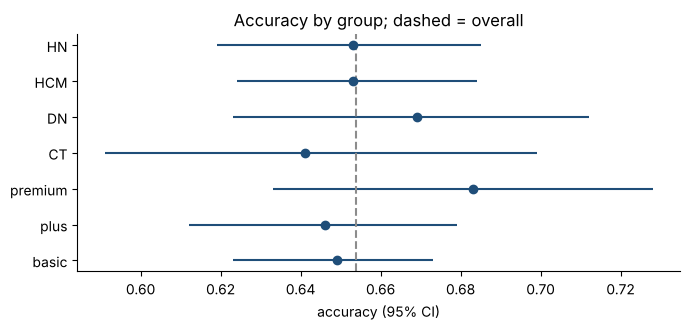

In [4]:
def group_report(col):
    rows = []
    vals = X_test[col].to_numpy()
    for v in sorted(set(vals)):
        idx = np.where(vals == v)[0]
        acc = correct[idx].mean()
        boots = bootstrap(lambda i: correct[i].mean(), B=500, idx_pool=idx)
        auc = roc_auc_score(y_arr[idx], p_test[idx]) if len(set(y_arr[idx])) == 2 else np.nan
        lo, hi = np.quantile(boots, [0.025, 0.975])
        rows.append({col: v, "n": len(idx), "accuracy": acc, "ci_low": lo, "ci_high": hi, "auc": auc,
                     "differs_from_overall": bool(hi < correct.mean() or lo > correct.mean())})
    return pd.DataFrame(rows).set_index(col).round(3)
group_plan, group_city = group_report("plan"), group_report("city")
print(group_plan.to_string()); print(); print(group_city.to_string())
fig, ax = plt.subplots(figsize=(7, 3.4))
allg = pd.concat([group_plan, group_city])
pos = np.arange(len(allg))
ax.errorbar(allg["accuracy"], pos, xerr=[allg["accuracy"] - allg["ci_low"], allg["ci_high"] - allg["accuracy"]], fmt="o", color=BLUE)
ax.axvline(correct.mean(), ls="--", color=GRAY); ax.set_yticks(pos); ax.set_yticklabels(allg.index); ax.set_xlabel("accuracy (95% CI)"); ax.set_title("Accuracy by group; dashed = overall")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `np.where(vals == v)[0]`: chọn các dòng thi thuộc nhóm `v`.
- `bootstrap(..., idx_pool=idx)`: khoảng tin cậy riêng cho nhóm: nhóm nhỏ sẽ có khoảng rộng.
- `differs_from_overall`: đánh dấu nhóm có **cả khoảng** nằm dưới hoặc trên mức tổng: chỉ khi đó mới có bằng chứng nhóm khác biệt.
- `ax.errorbar(...)`: vẽ mỗi nhóm một điểm kèm thanh sai số; đường đứt là mức tổng.

**Cách đọc.**
- **Con số:** số nhóm có khoảng tin cậy nằm hẳn khỏi mức tổng: **0** trên 7 nhóm. Nhóm nhỏ nhất là **CT** với n = 340 và khoảng rộng 0,108.
- **Bức tranh:** nếu hầu hết khoảng chồng lên mức tổng thì chưa có bằng chứng mô hình đối xử khác nhau giữa các nhóm, **dù** con số điểm có lệch. Ngược lại, nhóm nhỏ cho khoảng quá rộng nên **không kết luận được gì** (khác với "ổn").
- **Quy tắc đọc:** thẻ mô hình ghi rõ từng nhóm quan trọng, kèm n và khoảng; nhóm quá nhỏ thì ghi "chưa đủ dữ liệu".

**Mang về chặng 3:** báo cáo theo nhóm cần cỡ mẫu và khoảng, không chỉ trung bình.

## Chặng 3: Hiệu chuẩn, nói 70% thì có đúng 70% không

**Câu hỏi:** khi mô hình nói "xác suất quay lại 0,3", thực tế bao nhiêu khách quay lại?

 mean_pred  actual   n
     0.200   0.238 240
     0.307   0.312 240
     0.371   0.388 240
     0.432   0.442 240
     0.493   0.483 240
     0.554   0.546 240
     0.618   0.629 240
     0.689   0.646 240
     0.773   0.738 240
     0.877   0.854 240
largest gap between predicted and actual: 0.043 | mean gap: 0.02


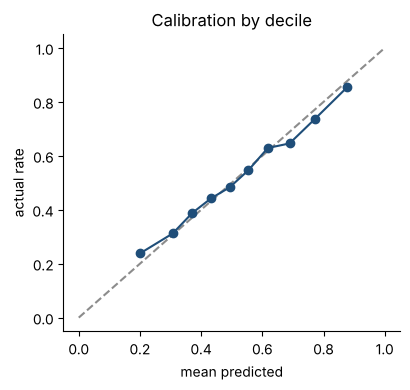

In [5]:
bins = pd.qcut(p_test, 10, duplicates="drop")
calib = pd.DataFrame({"p": p_test, "y": y_arr, "bin": bins}).groupby("bin", observed=True).agg(mean_pred=("p", "mean"), actual=("y", "mean"), n=("y", "size")).round(3)
print(calib.to_string(index=False))
gap = (calib["mean_pred"] - calib["actual"]).abs()
print("largest gap between predicted and actual:", round(float(gap.max()), 3), "| mean gap:", round(float(gap.mean()), 3))
fig, ax = plt.subplots(figsize=(4.2, 4))
ax.plot([0, 1], [0, 1], ls="--", color=GRAY); ax.plot(calib["mean_pred"], calib["actual"], marker="o", color=BLUE)
ax.set_xlabel("mean predicted"); ax.set_ylabel("actual rate"); ax.set_title("Calibration by decile")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `pd.qcut(p_test, 10)`: chia khách thành 10 nhóm bằng nhau theo xác suất dự đoán.
- `.agg(mean_pred=("p", "mean"), actual=("y", "mean"))`: trong mỗi nhóm: xác suất trung bình mô hình nói, và tỷ lệ quay lại thật.
- `gap`: độ lệch giữa hai số: nhỏ thì mô hình **hiệu chuẩn tốt**, dùng xác suất làm tiền bạc được.
- `ax.plot([0, 1], [0, 1], ls="--")`: đường chéo là hiệu chuẩn hoàn hảo; càng gần đường này càng tốt.

**Cách đọc.**
- **Con số:** độ lệch lớn nhất giữa xác suất đoán và tỷ lệ thật qua 10 nhóm là **0,043**; trung bình **0,020**.
- **Bức tranh:** hồi quy logistic thường được hiệu chuẩn khá tốt khi dữ liệu không trôi (D3). Với 240 khách mỗi phần mười, độ lệch vài phần trăm vẫn nằm trong nhiễu. Hiệu chuẩn quan trọng khi ta dùng xác suất để **tính tiền** (H2, chặng 4), không chỉ để xếp hạng.
- **Quy tắc đọc:** nếu lệch hệ thống (đường cong luôn nằm một phía của đường chéo), hãy hiệu chuẩn lại (D3) trước khi dùng xác suất làm ngưỡng chi phí.

**Mang về chặng 4:** thẻ mô hình ghi cả độ hiệu chuẩn, không chỉ độ chính xác.

## Chặng 4: Giới hạn, ngoài vùng đã học

**Câu hỏi:** mô hình tin cậy cho dạng khách nào, và dạng nào không nên dùng?

In [6]:
ranges = X_train[num_cols].agg(["min", "max"]).T
q = X_train[num_cols].quantile([0.01, 0.99]).T
ranges["p01"], ranges["p99"] = q[0.01], q[0.99]
print(ranges.round(1).to_string())
def in_support(frame):
    ok = pd.Series(True, index=frame.index)
    for c in num_cols:
        ok &= frame[c].between(ranges.loc[c, "min"], ranges.loc[c, "max"]) | frame[c].isna()
    return ok
test_in = in_support(X_test).to_numpy()
print("share of test inside training ranges:", round(float(test_in.mean()), 3))
new_cust = make_customers(2000, seed=42, month=0)
new_cust = new_cust.assign(tenure_months=new_cust["tenure_months"] * 2)
print("if tenure doubled (new type of customer): inside range share =", round(float(in_support(new_cust).mean()), 3))
base_row = X_test.iloc[[0]].copy()
what_if = pd.DataFrame({"tenure_months": [0, 6, 12, 24, 48, 96]})
rows = pd.concat([base_row.assign(tenure_months=t) for t in what_if["tenure_months"]], ignore_index=True)
what_if["proba"] = model.predict_proba(rows)[:, 1].round(3)
print(what_if.to_string(index=False))

                 min   max  p01   p99
tenure_months    1.0  72.0  3.0  52.0
monthly_spend    0.3   7.5  0.4   4.6
visits_last_30d  0.0  12.0  0.0   9.0
complaints       0.0   5.0  0.0   2.0
share of test inside training ranges: 0.997
if tenure doubled (new type of customer): inside range share = 0.929
 tenure_months  proba
             0  0.346
             6  0.398
            12  0.453
            24  0.564
            48  0.759
            96  0.949


**Giải thích từng dòng**

- `X_train[num_cols].agg(["min", "max"])`: khoảng giá trị mỗi cột số **trong dữ liệu học**: ngoài khoảng này mô hình chỉ đang ngoại suy.
- `in_support(frame)`: kiểm một bảng có nằm trong khoảng đã học không.
- `new_cust.assign(tenure_months=... * 2)`: giả lập một dạng khách mới (gắn bó lâu gấp đôi) để xem có bị chặn ra khỏi vùng đã học không.
- `what_if`: kiểm tra "nếu" một cột đổi dần, các cột khác giữ nguyên: xác suất đổi có hợp lý không (nên tăng khi gắn bó lâu hơn).

**Cách đọc.**
- **Con số:** 99,7% khách thi nằm trong khoảng đã học; khi nhân đôi thời gian gắn bó chỉ còn 93,0%. Bảng "nếu": gắn bó [0, 6, 12, 24, 48, 96] tháng cho xác suất [0.346, 0.398, 0.453, 0.564, 0.759, 0.949].
- **Bức tranh:** ngoài vùng đã học, mô hình tuyến tính vẫn trả ra con số trơn tru (kéo theo đường thẳng) dù không có bằng chứng; hàm dự đoán ở H2 nên cảnh báo hoặc từ chối. Bảng "nếu" cũng là cách nhanh để người dùng nghiệp vụ kiểm tra xem mô hình **có hợp lẽ thường không**.
- **Quy tắc đọc:** phần "giới hạn" của thẻ mô hình ghi: khoảng giá trị đã học, dạng khách chưa thấy, và các điều mô hình **không** biết (ví dụ chiến dịch khuyến mãi, thay đổi giá).

**Mang về chặng 5:** ghi vùng đã học và kiểm "nếu" trong thẻ.

## Chặng 5: Sinh thẻ mô hình từ các con số

**Câu hỏi:** gom hết lại thành một trang người khác đọc được, không gõ tay con số nào?

In [7]:
import datetime
def fmt(x): return f"{x:.3f}".replace(".", ",")
weak = group_city[group_city["differs_from_overall"]].index.tolist() + group_plan[group_plan["differs_from_overall"]].index.tolist()
card = f"""# Model card: customer return prediction (v1)

## Purpose
Estimate the probability that a customer returns within 30 days, to decide who gets a voucher.
Not for: credit decisions, pricing, anything about an individual's rights.

## Data
Synthetic customer table, {len(X_train)} training rows, {len(X_test)} test rows. Features: {', '.join(num_cols + cat_cols)}.
Trained on {datetime.date.today().isoformat()}.

## Performance on the held-out test set
- Accuracy: {fmt(correct.mean())} (95% CI {fmt(ci(acc_boot)[0])} to {fmt(ci(acc_boot)[1])})
- AUC: {fmt(roc_auc_score(y_arr, p_test))} (95% CI {fmt(ci(auc_boot)[0])} to {fmt(ci(auc_boot)[1])})
- Calibration: largest decile gap {fmt(gap.max())}, mean gap {fmt(gap.mean())}

## Performance by group (accuracy, n)
""" + "\n".join(f"- {c}: {fmt(r['accuracy'])} (n={int(r['n'])}, CI {fmt(r['ci_low'])} to {fmt(r['ci_high'])})" for c, r in allg.iterrows()) + f"""

Groups clearly different from overall: {weak if weak else 'none detected at this sample size'}.

## Limits
- Trained on tenure up to {int(ranges.loc['tenure_months', 'max'])} months, spend {ranges.loc['monthly_spend', 'min']:.1f} to {ranges.loc['monthly_spend', 'max']:.1f}; outside this, treat output as unreliable.
- Quality was checked on a single time period; it drifts over time (see monitoring notebook).
- Threshold 0.5 is a default; the business threshold is set from voucher cost.
"""
print(card)

# Model card: customer return prediction (v1)

## Purpose
Estimate the probability that a customer returns within 30 days, to decide who gets a voucher.
Not for: credit decisions, pricing, anything about an individual's rights.

## Data
Synthetic customer table, 3600 training rows, 2400 test rows. Features: tenure_months, monthly_spend, visits_last_30d, complaints, plan, city.
Trained on 2026-11-03.

## Performance on the held-out test set
- Accuracy: 0,654 (95% CI 0,635 to 0,673)
- AUC: 0,712 (95% CI 0,693 to 0,732)
- Calibration: largest decile gap 0,043, mean gap 0,020

## Performance by group (accuracy, n)
- basic: 0,649 (n=1336, CI 0,623 to 0,673)
- plus: 0,646 (n=673, CI 0,612 to 0,679)
- premium: 0,683 (n=391, CI 0,633 to 0,728)
- CT: 0,641 (n=340, CI 0,591 to 0,699)
- DN: 0,669 (n=378, CI 0,623 to 0,712)
- HCM: 0,653 (n=945, CI 0,624 to 0,684)
- HN: 0,653 (n=737, CI 0,619 to 0,685)

Groups clearly different from overall: none detected at this sample size.

## Limits
- Trained o

**Giải thích từng dòng**

- `def fmt(x)`: định dạng số với dấu phẩy thập phân kiểu Việt cho đọc dễ.
- `weak = ...`: danh sách nhóm có khoảng tin cậy nằm hẳn khỏi mức tổng (chặng 2).
- `card = f"""..."""`: ghép thẻ từ các biến đã tính: con số nào trong thẻ cũng đến từ code, nên sửa dữ liệu hay mô hình thì thẻ tự cập nhật.
- `ranges.loc[...]`: điền phần "Giới hạn" từ khoảng đã học (chặng 4).

**Cách đọc.**
- **Con số:** thẻ dài 30 dòng, chứa 9 khoảng tin cậy, và nhóm khác biệt rõ rệt: không có.
- **Bức tranh:** thẻ nói **cả điểm mạnh lẫn điểm yếu**, có mục "Không dùng cho". Ai nhận mô hình đều đọc được trong 2 phút. Vì được sinh từ code, mỗi lần huấn luyện lại ta có một thẻ mới đúng với mô hình mới.
- **Lưu ý:** thẻ này dùng dữ liệu dựng; thẻ thật cần thêm nguồn dữ liệu, người chịu trách nhiệm, ngày xem xét lại và cách liên hệ khi có sự cố.

**Mang về:** khoảng tin cậy, báo cáo theo nhóm, hiệu chuẩn, giới hạn, và thẻ sinh từ code: báo cáo trung thực.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Một con số tổng che giấu nhóm yếu và sai số. |
| 1 | Bootstrap cho khoảng tin cậy mọi chỉ số, nhất là khi n nhỏ. |
| 2 | Báo cáo theo nhóm kèm n; khoảng rộng nghĩa là chưa kết luận được. |
| 3 | Hiệu chuẩn cho biết xác suất có dùng làm tiền bạc được không. |
| 4 | Ghi vùng dữ liệu đã học và kiểm 'nếu' bằng lẽ thường. |
| 5 | Sinh thẻ mô hình từ code để luôn đúng với mô hình hiện tại. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Tờ hướng dẫn trong hộp thuốc | thẻ mô hình | `card` |
| Sai số của phép đo | khoảng tin cậy | `bootstrap`, `ci` |
| Hiệu quả theo từng nhóm tuổi | chất lượng theo nhóm | `group_report` |
| Nói 70% thì đúng 70% | hiệu chuẩn | `calib`, `gap` |
| Không dùng cho trẻ em | giới hạn | `ranges`, `in_support` |
| Hỏi 'nếu' thử | phân tích what-if | `what_if` |

**Thử thách tự làm**

1. Ở chặng 1, đổi `B=1000` thành 100 rồi 5000. Khoảng tin cậy đổi thế nào? Số lần lặp ảnh hưởng gì?
2. Ở chặng 2, thêm nhóm theo `tenure_months` chia ba mức (`pd.cut`). Có nhóm nào khác biệt rõ không?
3. Ở chặng 5, thêm mục 'Người chịu trách nhiệm' và 'Ngày xem xét lại tiếp theo' vào thẻ.
4. Ở chặng 4, làm bảng 'nếu' cho `complaints` từ 0 đến 6. Hướng thay đổi có hợp lẽ thường không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tính khoảng tin cậy bootstrap cho một chỉ số.
- [ ] Báo cáo chất lượng theo nhóm kèm cỡ mẫu.
- [ ] Vẽ và đọc đường hiệu chuẩn.
- [ ] Ghi giới hạn của mô hình từ khoảng dữ liệu đã học.
- [ ] Sinh được thẻ mô hình từ code.

## Phần thưởng (Tip pro): Sang H5: dự án tổng kết


Đến lúc ghép tất cả: từ dữ liệu thô đến mô hình, đánh giá, lưu, hàm dự đoán, thẻ mô hình. H5 là một dự án trọn vẹn kèm bài tập tự làm có ô trống và lời giải.